# Trabalho de Ciência de Dados — Manutenção Preditiva

**Aluno:** Eliton Mota Lamim  
**Tema:** Análise de dados aplicada à manutenção preditiva de equipamentos industriais  
**Ambiente:** Google Colab  
**Base de dados:** AI4I 2020 Predictive Maintenance Dataset (Kaggle)

## 1. Motivação

A manutenção preditiva utiliza dados de operação para identificar padrões associados a possíveis falhas. A escolha deste tema está relacionada ao interesse em compreender como informações como temperatura, rotação, torque e desgaste podem apoiar decisões de manutenção.

O objetivo deste trabalho não é apenas aplicar um algoritmo de Machine Learning, mas **fazer perguntas aos dados, encontrar padrões e interpretar os resultados sob uma perspectiva de engenharia**.

> **Importante:** os resultados apresentados neste notebook devem ser obtidos pela execução do código sobre o arquivo CSV utilizado. Não serão inventados valores ou conclusões.


## 2. Problema de pesquisa

**Pergunta central:**

> É possível identificar, a partir das condições de operação registradas, padrões associados à ocorrência de falhas em máquinas?

### Perguntas de investigação

1. Qual é o perfil geral dos dados e das máquinas analisadas?
2. Qual é a frequência de registros com e sem falha?
3. As condições de operação diferem entre registros com e sem falha?
4. O desgaste da ferramenta apresenta associação com a ocorrência de falhas?
5. Temperatura, rotação e torque apresentam padrões diferentes entre as classes?
6. Quais tipos de falha aparecem com maior frequência?
7. A combinação das variáveis disponíveis consegue classificar registros com e sem falha?
8. Quais variáveis apresentam maior importância para o modelo?

Essas perguntas conduzem a análise desde a exploração dos dados até a aplicação de Machine Learning.


## 3. Por que este dataset?

O dataset AI4I 2020 foi escolhido por apresentar variáveis relacionadas à operação de máquinas e informações sobre ocorrência de falhas.

A base permite trabalhar com:

- análise exploratória;
- comparação entre grupos;
- visualização de padrões;
- classificação;
- avaliação de modelos;
- interpretação da importância das variáveis.

A proposta é utilizar a base como um **exercício acadêmico de Ciência de Dados**, sem assumir que o modelo esteja pronto para utilização em uma máquina industrial real.


## 4. Bibliotecas


In [ ]:
import io
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

print("Bibliotecas carregadas com sucesso.")


Bibliotecas carregadas com sucesso.


## 5. Carregamento da planilha

Baixe o arquivo CSV do dataset no Kaggle e carregue-o quando o Google Colab solicitar.


In [ ]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("Nenhum arquivo foi enviado.")

filename = next(iter(uploaded))
raw = uploaded[filename]

try:
    df = pd.read_csv(
        io.BytesIO(raw),
        sep=None,
        engine="python",
        encoding="utf-8-sig"
    )
except UnicodeDecodeError:
    df = pd.read_csv(
        io.BytesIO(raw),
        sep=None,
        engine="python",
        encoding="latin-1"
    )

df.columns = df.columns.astype(str).str.strip()

print(f"Arquivo carregado: {filename}")
print(f"Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())


Saving predictive_maintenance.csv to predictive_maintenance.csv
Arquivo carregado: predictive_maintenance.csv
Dimensões: 10000 linhas e 10 colunas


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


## 6. Conhecendo os dados

Antes de fazer qualquer previsão, é necessário verificar a estrutura e a qualidade da base.

Nesta etapa serão analisados:

- nomes das variáveis;
- tipos de dados;
- valores ausentes;
- registros duplicados;
- estatísticas descritivas.


In [ ]:
print("Nomes das colunas:")
print(df.columns.tolist())

print("\nTipos de dados:")
display(df.dtypes.rename("tipo de dado").to_frame())

print("\nValores ausentes por coluna:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .rename("valores ausentes")
      .to_frame()
)

print(f"\nLinhas duplicadas: {df.duplicated().sum()}")

print("\nEstatísticas descritivas:")
display(df.describe(include="all").T)


Nomes das colunas:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']

Tipos de dados:


,tipo de dado
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Target,int64
Failure Type,object



Valores ausentes por coluna:


,valores ausentes
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Failure Type,0



Linhas duplicadas: 0

Estatísticas descritivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,L57163,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Target,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
Failure Type,10000,6,No Failure,9652,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Definição da variável-alvo

A variável-alvo representa a ocorrência de falha.

Na base AI4I, normalmente ela aparece como `Machine failure`.

O código abaixo identifica automaticamente nomes comuns para evitar depender de uma grafia específica.


In [ ]:
def normalizar_nome(nome):
    return (
        str(nome).strip().lower()
        .replace("_", " ")
        .replace("-", " ")
    )

possiveis_alvos = [
    "machine failure", "failure", "falha",
    "falha da máquina", "target", "class", "y"
]

mapa_colunas = {normalizar_nome(c): c for c in df.columns}

target_col = next(
    (mapa_colunas[n] for n in possiveis_alvos if n in mapa_colunas),
    None
)

if target_col is None:
    print("Colunas disponíveis:", df.columns.tolist())
    raise ValueError("Não foi possível identificar a coluna-alvo.")

print("Variável-alvo identificada:", target_col)

print("\nContagem por classe:")
display(
    df[target_col]
      .value_counts(dropna=False)
      .rename("quantidade")
      .to_frame()
)

print("\nPercentual por classe (%):")
display(
    (df[target_col].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .rename("percentual")
    .to_frame()
)


Variável-alvo identificada: Target

Contagem por classe:


,quantidade
Target,
0,9661
1,339



Percentual por classe (%):


,percentual
Target,
0,96.61
1,3.39


## 8. Pergunta 1 — Qual é a frequência de falhas?

A primeira pergunta permite entender o equilíbrio entre os registros com e sem falha.

Essa informação é importante porque uma quantidade muito menor de falhas pode fazer com que a acurácia, isoladamente, seja uma métrica enganosa.


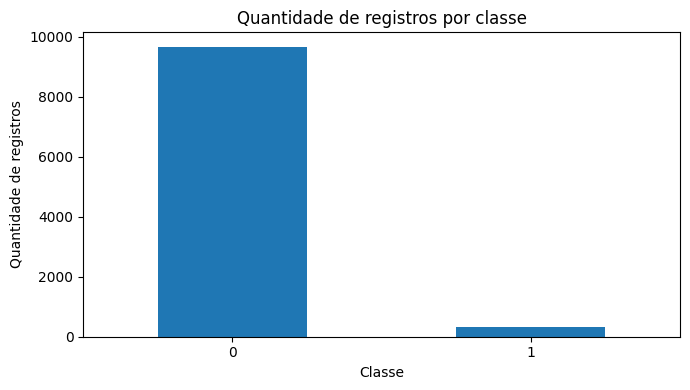

In [ ]:
contagem = df[target_col].astype(str).value_counts()

plt.figure(figsize=(7, 4))
contagem.plot(kind="bar")
plt.title("Quantidade de registros por classe")
plt.xlabel("Classe")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Pergunta 2 — Como são as condições de operação?

Agora serão observadas as distribuições das variáveis numéricas.

O objetivo é identificar a faixa de operação da base antes de comparar os registros com e sem falha.


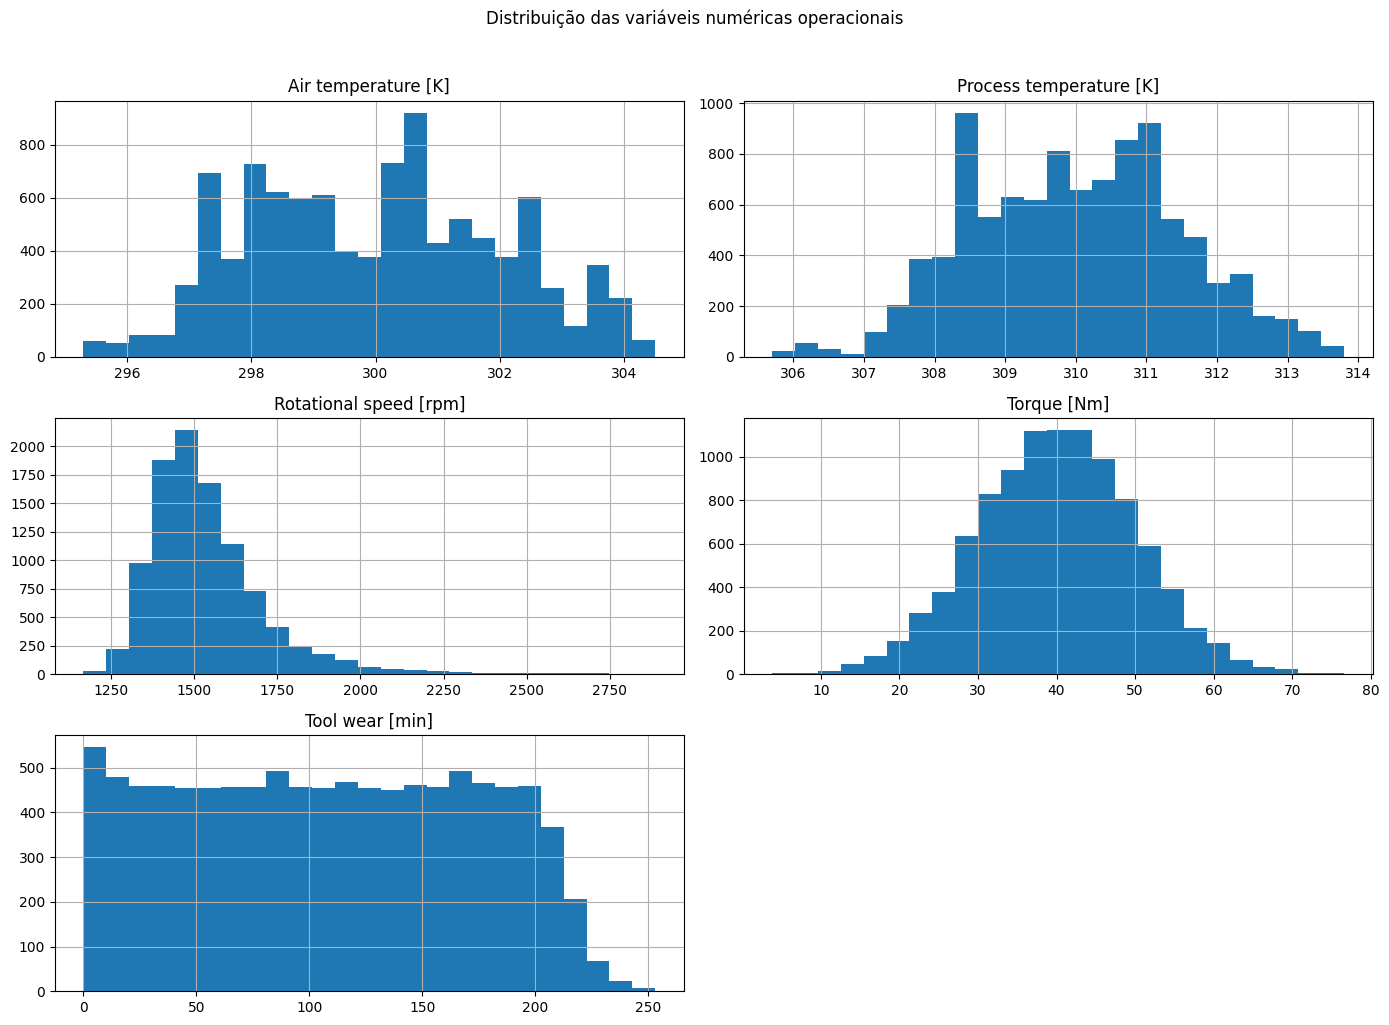

In [ ]:
# Para os gráficos exploratórios, manter somente variáveis numéricas operacionais.
# Excluir identificadores, a variável-alvo e rótulos/indicadores de falha.
colunas_nao_operacionais = {
    "udi", "product id", "machine failure", "failure", "falha",
    "target", "class", "y", "failure type",
    "twf", "hdf", "pwf", "osf", "rnf"
}
numeric_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if normalizar_nome(c) not in colunas_nao_operacionais
    and c != target_col
]

if numeric_cols:
    df[numeric_cols].hist(figsize=(14, 10), bins=25)
    plt.suptitle("Distribuição das variáveis numéricas operacionais", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Não foram encontradas colunas numéricas operacionais.")


## 10. Pergunta 3 — As condições de operação diferem entre registros com e sem falha?

Uma forma inicial de investigar essa questão é comparar as médias das variáveis numéricas por classe.

**Atenção:** diferença de média não significa, por si só, que uma variável causa a falha. Ela apenas indica um padrão observado nos dados.


Médias das variáveis operacionais por classe da variável-alvo:


Target,0,1
Air temperature [K],299.974,300.886
Process temperature [K],309.996,310.290
Rotational speed [rpm],1540.260,1496.487
Torque [Nm],39.630,50.168
Tool wear [min],106.694,143.782


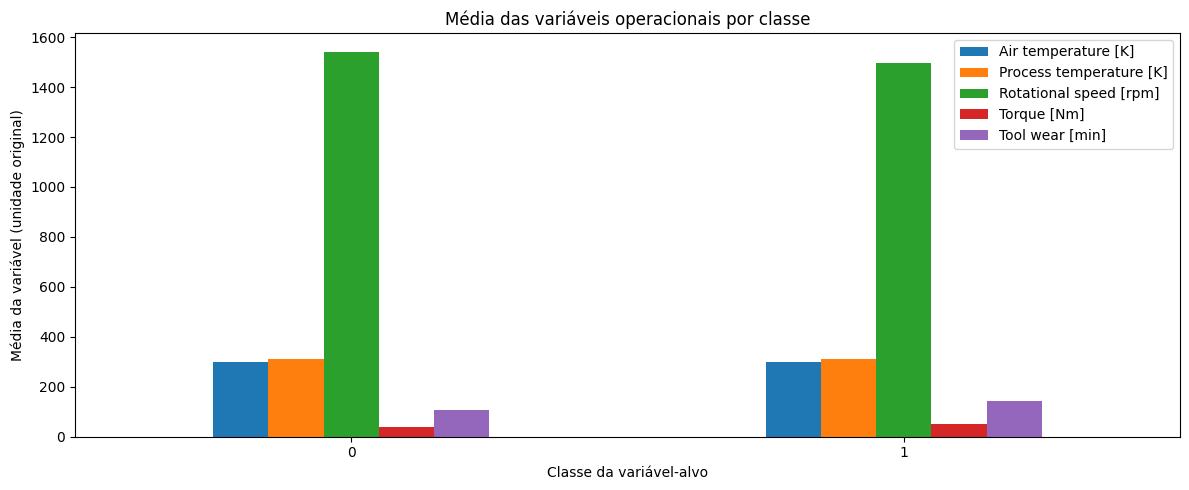

In [ ]:
# Comparar somente variáveis operacionais; nunca incluir a variável-alvo ou identificadores.
colunas_excluir_comparacao = {
    normalizar_nome(target_col), "udi", "product id",
    "machine failure", "failure", "falha", "target", "class", "y",
    "failure type", "twf", "hdf", "pwf", "osf", "rnf"
}
cols_comparacao = [
    c for c in numeric_cols
    if normalizar_nome(c) not in colunas_excluir_comparacao
    and c != target_col
]

if cols_comparacao:
    comparacao = df.groupby(target_col)[cols_comparacao].mean(numeric_only=True).T
    print("Médias das variáveis operacionais por classe da variável-alvo:")
    display(comparacao.round(3))

    # Mostrar até seis variáveis operacionais para manter o gráfico legível.
    cols_plot = cols_comparacao[:6]
    ax = df.groupby(target_col)[cols_plot].mean(numeric_only=True).plot(
        kind="bar", figsize=(12, 5)
    )
    ax.set_title("Média das variáveis operacionais por classe")
    ax.set_xlabel("Classe da variável-alvo")
    ax.set_ylabel("Média da variável (unidade original)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Não há variáveis numéricas operacionais para comparar.")


## 11. Pergunta 4 — O desgaste apresenta relação com a ocorrência de falhas?

O desgaste da ferramenta é uma variável particularmente interessante para manutenção.

Nesta etapa, quando a coluna estiver disponível, será comparada sua distribuição entre os registros sem falha e com falha.


Variável de desgaste: Tool wear [min]


,count,mean,median,min,max
Target,,,,,
0,9661,106.693717,107.0,0,246
1,339,143.781711,165.0,0,253


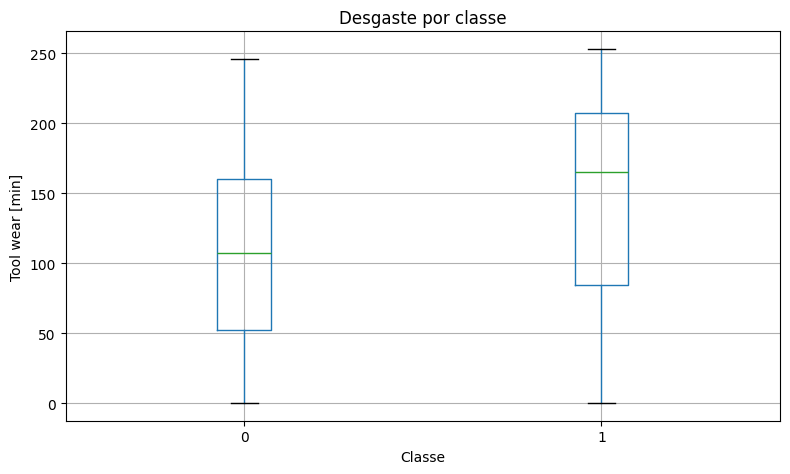

In [ ]:
def encontrar_coluna(padroes):
    mapa = {normalizar_nome(c): c for c in df.columns}
    for p in padroes:
        if p in mapa:
            return mapa[p]
    return None

wear_col = next((c for c in df.columns if normalizar_nome(c).startswith("tool wear") or normalizar_nome(c).startswith("desgaste")), None)

if wear_col is not None:
    print("Variável de desgaste:", wear_col)
    display(
        df.groupby(target_col)[wear_col]
          .agg(["count", "mean", "median", "min", "max"])
    )

    df.boxplot(column=wear_col, by=target_col, figsize=(8, 5))
    plt.title("Desgaste por classe")
    plt.suptitle("")
    plt.xlabel("Classe")
    plt.ylabel(wear_col)
    plt.tight_layout()
    plt.show()
else:
    print("Variável de desgaste não encontrada na base.")


## 12. Pergunta 5 — Quais tipos de falha aparecem com maior frequência?

Quando a base contém indicadores específicos (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`), eles podem ser usados para descrever a frequência dos modos de falha. Se esses indicadores não estiverem disponíveis, o código utiliza a coluna `Failure Type`, quando existente.

**Importante:** `Failure Type` é uma informação de diagnóstico e não será usada como entrada dos modelos. Também será verificada sua consistência com a variável-alvo, pois divergências entre os rótulos precisam ser reconhecidas na interpretação dos resultados.


### Observação sobre a consistência dos rótulos

Na base analisada, a variável `Target` indica **339 registros de falha**. Já a coluna `Failure Type` apresenta **348 registros com rótulos diferentes de `No Failure`**. A tabela de contingência mostra duas diferenças específicas:

- **9 registros** têm `Target = 1`, mas `Failure Type = No Failure`.
- **18 registros** têm `Target = 0`, mas `Failure Type = Random Failures`.

Portanto, as duas colunas não são totalmente consistentes entre si. Neste projeto, `Target` foi definida previamente como variável-alvo para o treinamento e a avaliação dos modelos. `Failure Type` é utilizada somente na análise exploratória para descrever os rótulos de falha e verificar a consistência da base; ela não é fornecida como entrada aos modelos.

Essa divergência deve ser considerada uma limitação dos rótulos do dataset. Não é possível determinar apenas por esta tabela por que esses registros foram rotulados de forma diferente. Por isso, os resultados dos modelos devem ser interpretados como desempenho na previsão de `Target`, e não como uma validação independente de cada tipo de falha.


Indicadores TWF/HDF/PWF/OSF/RNF não encontrados. Usando a coluna 'Failure Type'.


,quantidade
Failure Type,
No Failure,9652
Heat Dissipation Failure,112
Power Failure,95
Overstrain Failure,78
Tool Wear Failure,45
Random Failures,18


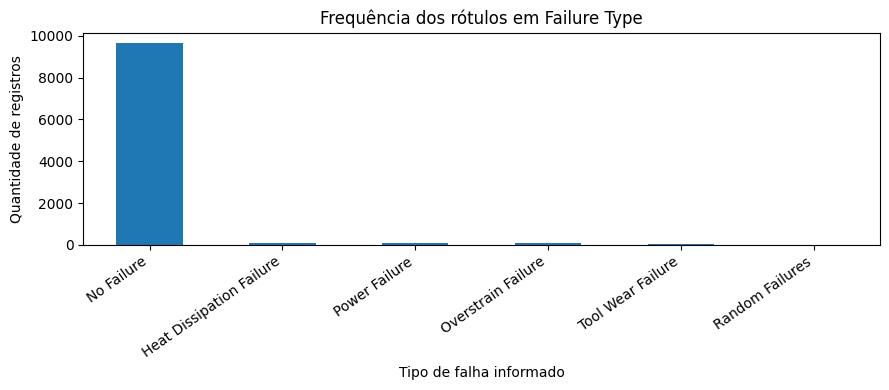


Conferência entre a variável-alvo e Failure Type:


Failure Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure,All
Target,,,,,,,
0,0,9643,0,0,18,0,9661
1,112,9,78,95,0,45,339
All,112,9652,78,95,18,45,10000


Interpretação: se houver registros classificados como falha pela variável-alvo e rotulados como 'No Failure' (ou o inverso), há divergência entre os campos. A coluna Failure Type é usada aqui apenas para EDA e é excluída dos modelos.


In [ ]:
failure_cols = []
for nome in ["TWF", "HDF", "PWF", "OSF", "RNF"]:
    for c in df.columns:
        if normalizar_nome(c) == normalizar_nome(nome):
            failure_cols.append(c)
            break

failure_type_col = next(
    (c for c in df.columns if normalizar_nome(c) == "failure type"),
    None
)

if failure_cols:
    frequencias = {
        c: int((pd.to_numeric(df[c], errors="coerce").fillna(0) == 1).sum())
        for c in failure_cols
    }
    failure_df = (
        pd.Series(frequencias, name="quantidade")
        .sort_values(ascending=False)
        .to_frame()
    )
    print("Frequência dos indicadores de modo de falha (cada indicador pode contar ocorrências próprias):")
    display(failure_df)

    failure_df.plot(kind="bar", figsize=(8, 4), legend=False)
    plt.title("Frequência dos indicadores de modos de falha")
    plt.xlabel("Indicador")
    plt.ylabel("Quantidade de registros")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
elif failure_type_col is not None:
    print(f"Indicadores TWF/HDF/PWF/OSF/RNF não encontrados. Usando a coluna '{failure_type_col}'.")
    freq_type = df[failure_type_col].fillna("Valor ausente").astype(str).value_counts()
    display(freq_type.rename("quantidade").to_frame())

    freq_type.plot(kind="bar", figsize=(9, 4), legend=False)
    plt.title("Frequência dos rótulos em Failure Type")
    plt.xlabel("Tipo de falha informado")
    plt.ylabel("Quantidade de registros")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("A base não contém os indicadores TWF/HDF/PWF/OSF/RNF nem a coluna Failure Type.")

if failure_type_col is not None:
    print("\nConferência entre a variável-alvo e Failure Type:")
    tabela_consistencia = pd.crosstab(
        df[target_col].fillna("Ausente"),
        df[failure_type_col].fillna("Valor ausente"),
        margins=True
    )
    display(tabela_consistencia)
    print(
        "Interpretação: se houver registros classificados como falha pela variável-alvo "
        "e rotulados como 'No Failure' (ou o inverso), há divergência entre os campos. "
        "A coluna Failure Type é usada aqui apenas para EDA e é excluída dos modelos."
    )


## 13. Preparação dos dados para Machine Learning

Depois da análise exploratória, será feita a classificação entre registros com e sem falha.

Para reduzir o risco de vazamento de informação:

- identificadores como `UDI` e `Product ID` serão removidos;
- `Failure Type` e os indicadores específicos de falha (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) não serão usados como variáveis preditoras;
- o pré-processamento será ajustado dentro de um pipeline;
- os dados serão divididos em treino e teste com estratificação;
- o conjunto de teste ficará reservado para a avaliação final.


In [ ]:
y_original = df[target_col]

if y_original.isna().any():
    valid_mask = y_original.notna()
    data = df.loc[valid_mask].copy()
    y_original = data[target_col]
else:
    data = df.copy()

if pd.api.types.is_numeric_dtype(y_original):
    y = y_original.astype(int)
else:
    classes = sorted(y_original.astype(str).unique())
    if len(classes) != 2:
        raise ValueError(
            f"Este exemplo espera classificação binária; classes encontradas: {classes}"
        )
    mapa_classes = {classes[0]: 0, classes[1]: 1}
    y = y_original.astype(str).map(mapa_classes).astype(int)
    print("Codificação de classes:", mapa_classes)

# Variáveis que NÃO podem entrar no modelo.
# Failure Type é uma informação de diagnóstico/pós-falha e causaria vazamento de dados.
nomes_excluir = {
    "udi", "product id", "product_id",
    "failure type",
    "twf", "hdf", "pwf", "osf", "rnf"
}

X = data.drop(columns=[target_col]).copy()
colunas_excluir = [
    c for c in X.columns
    if normalizar_nome(c) in nomes_excluir
]
X = X.drop(columns=colunas_excluir, errors="ignore")
X = X.dropna(axis=1, how="all")

if y.nunique() < 2:
    raise ValueError("A variável-alvo precisa conter pelo menos duas classes.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Variáveis utilizadas no modelo:")
print(X.columns.tolist())
print(f"Treino: {X_train.shape[0]} registros")
print(f"Teste: {X_test.shape[0]} registros")
print(f"Classe positiva no treino: {y_train.mean() * 100:.2f}%")

if any(normalizar_nome(c) == "failure type" for c in X.columns):
    raise ValueError("ERRO: Failure Type ainda está no conjunto de entrada.")

print("OK: Failure Type não está sendo usada como variável de entrada.")


Variáveis utilizadas no modelo:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Treino: 8000 registros
Teste: 2000 registros
Classe positiva no treino: 3.39%
OK: Failure Type não está sendo usada como variável de entrada.


## 14. Baseline, comparação de modelos e otimização

A comparação inclui:

- **DummyClassifier (baseline):** prevê sempre a classe mais frequente e serve como referência simples;
- **Regressão Logística:** modelo linear de classificação;
- **Random Forest otimizada:** conjunto de árvores de decisão capaz de representar relações não lineares.

Será utilizada validação cruzada estratificada no conjunto de treinamento. A busca de hiperparâmetros da Random Forest será orientada pelo F1-score da classe de falha. O conjunto de teste não será usado para escolher hiperparâmetros.

Como a classe de falha é minoritária, a interpretação dará atenção especial à precisão, ao recall e ao F1-score, sem deixar de apresentar acurácia e ROC-AUC.


In [ ]:
# 1) Definir uma baseline e os modelos candidatos.
modelos_base = {
    "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
}

pipelines = {}
for nome, modelo in modelos_base.items():
    pipelines[nome] = Pipeline(steps=[
        ("preprocessamento", preprocessor),
        ("modelo", modelo)
    ])

# 2) Otimizar hiperparâmetros da Random Forest somente com os dados de treino.
rf_pipeline = Pipeline(steps=[
    ("preprocessamento", preprocessor),
    ("modelo", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

param_distributions = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [None, 10, 20],
    "modelo__min_samples_split": [2, 5],
    "modelo__min_samples_leaf": [1, 2]
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

busca_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)
busca_rf.fit(X_train, y_train)

pipelines["Random Forest otimizada"] = busca_rf.best_estimator_

print("Melhores hiperparâmetros da Random Forest:")
display(pd.Series(busca_rf.best_params_, name="valor").to_frame())
print(f"Melhor F1-score médio na validação cruzada da busca: {busca_rf.best_score_:.4f}")

# 3) Comparar os modelos por validação cruzada dentro do conjunto de treino.
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
linhas_cv = []
for nome, pipe in pipelines.items():
    cv_result = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1,
        error_score="raise"
    )
    linhas_cv.append({
        "Modelo": nome,
        "Acurácia CV (média)": cv_result["test_accuracy"].mean(),
        "Precisão CV (média)": cv_result["test_precision"].mean(),
        "Recall CV (média)": cv_result["test_recall"].mean(),
        "F1-score CV (média)": cv_result["test_f1"].mean(),
        "ROC-AUC CV (média)": cv_result["test_roc_auc"].mean()
    })

resultados_cv_df = pd.DataFrame(linhas_cv).set_index("Modelo")
print("Resultados médios da validação cruzada (somente dados de treinamento):")
display(resultados_cv_df.round(4))

# 4) Ajustar cada modelo de comparação no treino e avaliar uma única vez no teste.
resultados = []
for nome, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    try:
        prob = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, prob)
    except Exception:
        auc = np.nan

    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, pred),
        "Precisão (falha)": precision_score(y_test, pred, zero_division=0),
        "Recall (falha)": recall_score(y_test, pred, zero_division=0),
        "F1-score (falha)": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": auc
    })

resultados_df = pd.DataFrame(resultados).set_index("Modelo")
print("Comparação final no conjunto de teste:")
display(resultados_df.round(4))


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Melhores hiperparâmetros da Random Forest:


,valor
modelo__n_estimators,100
modelo__min_samples_split,5
modelo__min_samples_leaf,1
modelo__max_depth,20


Melhor F1-score médio na validação cruzada da busca: 0.6145
Resultados médios da validação cruzada (somente dados de treinamento):


,Acurácia CV (média),Precisão CV (média),Recall CV (média),F1-score CV (média),ROC-AUC CV (média)
Modelo,,,,,
Baseline (classe majoritária),0.9661,0.0000,0.0000,0.0000,0.5000
Regressão Logística,0.8205,0.1366,0.8081,0.2337,0.8999
Random Forest otimizada,0.9799,0.8711,0.4759,0.6145,0.9633


Comparação final no conjunto de teste:


,Acurácia,Precisão (falha),Recall (falha),F1-score (falha),ROC-AUC
Modelo,,,,,
Baseline (classe majoritária),0.9660,0.0000,0.0000,0.0000,0.500
Regressão Logística,0.8245,0.1418,0.8235,0.2419,0.907
Random Forest otimizada,0.9825,0.8511,0.5882,0.6957,0.965


## 15. Pergunta 6 — Como o modelo se comporta ao identificar falhas?

A matriz de confusão permite observar:

- verdadeiros positivos;
- verdadeiros negativos;
- falsos positivos;
- falsos negativos.

Em manutenção preditiva, o **falso negativo** merece atenção: representa um caso em que ocorreu uma falha, mas o modelo não a identificou.


Modelo selecionado para análise: Random Forest otimizada

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.85      0.59      0.70        68

    accuracy                           0.98      2000
   macro avg       0.92      0.79      0.84      2000
weighted avg       0.98      0.98      0.98      2000



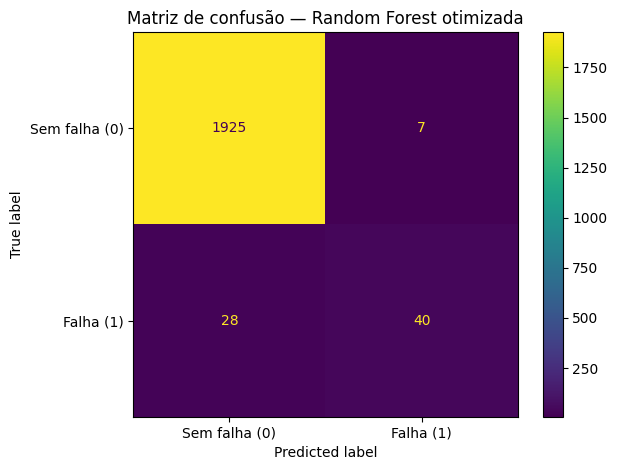

In [ ]:
modelo_escolhido_nome = resultados_df[
    "F1-score (falha)"
].idxmax()

modelo_escolhido = pipelines[modelo_escolhido_nome]
pred_escolhida = modelo_escolhido.predict(X_test)

print("Modelo selecionado para análise:", modelo_escolhido_nome)
print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        pred_escolhida,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    pred_escolhida,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sem falha (0)", "Falha (1)"]
)

disp.plot(values_format="d")
plt.title(f"Matriz de confusão — {modelo_escolhido_nome}")
plt.tight_layout()
plt.show()


## 16. Pergunta 7 — Quais variáveis mais contribuem para a classificação?

A Random Forest permite calcular uma medida de importância das variáveis.

Essa medida mostra quais atributos foram mais utilizados pelo modelo para realizar suas divisões. **Ela não prova que uma variável causa a falha.**


,Variável,Importância
2,num__Rotational speed [rpm],0.3034
3,num__Torque [Nm],0.2988
4,num__Tool wear [min],0.2043
0,num__Air temperature [K],0.1030
1,num__Process temperature [K],0.0706
6,cat__Type_L,0.0091
7,cat__Type_M,0.0072
5,cat__Type_H,0.0036


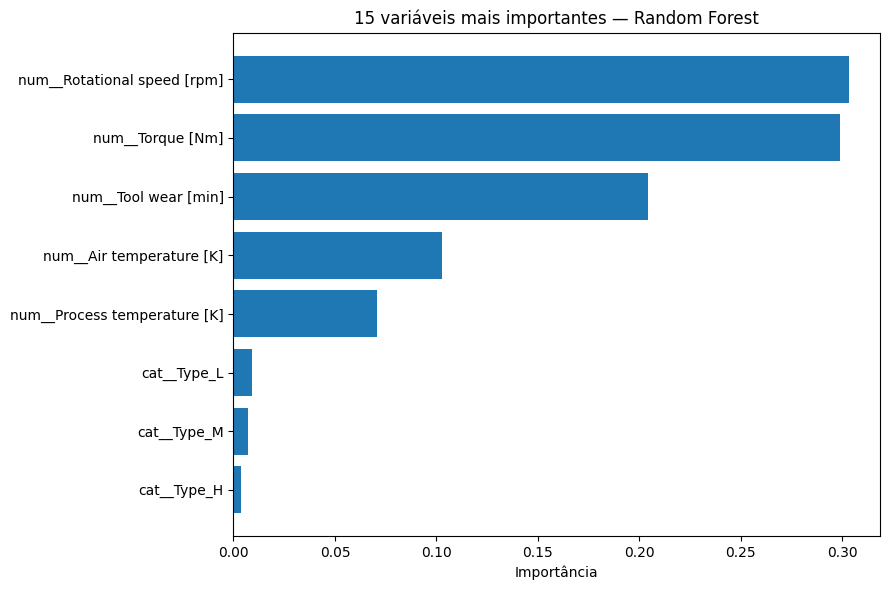

In [ ]:
rf_pipe = pipelines.get("Random Forest otimizada")

if rf_pipe is not None:
    feature_names = (
        rf_pipe
        .named_steps["preprocessamento"]
        .get_feature_names_out()
    )

    importances = (
        rf_pipe
        .named_steps["modelo"]
        .feature_importances_
    )

    importancia_df = pd.DataFrame({
        "Variável": feature_names,
        "Importância": importances
    }).sort_values(
        "Importância",
        ascending=False
    )

    display(importancia_df.head(15).round(4))

    top = importancia_df.head(15).sort_values("Importância")

    plt.figure(figsize=(9, 6))
    plt.barh(
        top["Variável"],
        top["Importância"]
    )
    plt.title("15 variáveis mais importantes — Random Forest")
    plt.xlabel("Importância")
    plt.tight_layout()
    plt.show()


## 17. Discussão dos resultados. Pergunta 8 - Quais variáveis apresentam maior importância para o modelo?

A base analisada e a proporção de registros com falha são apresentadas no resumo numérico gerado pelo notebook. Como a classe de falha é minoritária, a acurácia isolada pode ser enganosa; por isso, a comparação considera também precisão, recall, F1-score e ROC-AUC.

A tabela de resultados no conjunto de teste permite comparar a baseline, a Regressão Logística e a Random Forest otimizada. A baseline indica o desempenho de uma estratégia simples que sempre prevê a classe majoritária. Um modelo de Machine Learning precisa ser avaliado em relação a essa referência, principalmente quando há forte desbalanceamento entre as classes.

A validação cruzada foi realizada apenas nos dados de treinamento. A busca de hiperparâmetros da Random Forest também utiliza somente o conjunto de treinamento; o conjunto de teste foi reservado para a comparação final.

Na manutenção preditiva, falsos negativos são especialmente importantes porque representam falhas reais que o modelo não identificou. Falsos positivos também têm custo, pois podem gerar inspeções desnecessárias. A escolha do modelo deve considerar esse equilíbrio e o contexto de aplicação.

A importância das variáveis calculada pela Random Forest ajuda a identificar quais atributos mais contribuíram para as decisões do modelo, mas não demonstra causalidade. Os resultados também dependem da qualidade e representatividade do dataset AI4I 2020 e não devem ser interpretados como validação de um sistema pronto para uso industrial.


In [ ]:
# Resumo numérico final
total = len(y)
falhas = int((y == 1).sum())

print("RESUMO FINAL")
print(f"Total de registros analisados: {total}")
print(f"Registros classificados como falha: {falhas}")
print(f"Percentual de falhas: {falhas / total:.2%}")

print("\nComparação dos modelos:")
display(resultados_df.round(4))

print("\nModelo selecionado para análise detalhada:", modelo_escolhido_nome)
print(
    "F1-score da classe de falha:",
    round(resultados_df.loc[
        modelo_escolhido_nome, "F1-score (falha)"
    ], 4)
)
print(
    "Recall da classe de falha:",
    round(resultados_df.loc[
        modelo_escolhido_nome, "Recall (falha)"
    ], 4)
)


RESUMO FINAL
Total de registros analisados: 10000
Registros classificados como falha: 339
Percentual de falhas: 3.39%

Comparação dos modelos:


,Acurácia,Precisão (falha),Recall (falha),F1-score (falha),ROC-AUC
Modelo,,,,,
Baseline (classe majoritária),0.9660,0.0000,0.0000,0.0000,0.500
Regressão Logística,0.8245,0.1418,0.8235,0.2419,0.907
Random Forest otimizada,0.9825,0.8511,0.5882,0.6957,0.965



Modelo selecionado para análise detalhada: Random Forest otimizada
F1-score da classe de falha: 0.6957
Recall da classe de falha: 0.5882


## 18. Conclusão

Neste trabalho foi realizada uma análise de dados aplicada à **manutenção preditiva**, utilizando o **AI4I 2020 Predictive Maintenance Dataset**. O objetivo foi investigar se variáveis relacionadas às condições de operação poderiam contribuir para identificar registros associados à ocorrência de falhas.

O projeto incluiu análise exploratória, preparação dos dados, prevenção de vazamento de informação, comparação com uma baseline, Regressão Logística, otimização da Random Forest, validação cruzada no conjunto de treinamento e avaliação final no conjunto de teste.

A base contém **10.000 registros**, dos quais **339 (3,39%)** têm `Target = 1`. Na avaliação do conjunto de teste, a **Random Forest otimizada** obteve **98,25% de acurácia**, **85,11% de precisão**, **58,82% de recall**, **F1-score de 0,6957** e **ROC-AUC de 0,965**. Embora tenha apresentado o melhor F1-score entre os modelos comparados, o recall de 58,82% indica que o modelo identificou pouco menos de seis em cada dez falhas reais do conjunto de teste; portanto, ainda deixou passar parte das falhas.

A baseline teve acurácia de 96,60%, mas precisão, recall e F1-score iguais a zero para a classe de falha. Isso demonstra por que a acurácia isolada pode ser enganosa em uma base desequilibrada. A Regressão Logística apresentou recall de 82,35%, mas precisão de 14,18%, mostrando que identificou mais falhas ao custo de gerar muitos falsos alarmes. A escolha do modelo depende, portanto, do equilíbrio entre falhas não detectadas e alarmes falsos, além dos custos envolvidos na aplicação real.

Também foi observada uma divergência entre `Target` e `Failure Type`: há 9 registros com `Target = 1` e `Failure Type = No Failure`, além de 18 registros com `Target = 0` e `Failure Type = Random Failures`. Os modelos foram treinados para prever `Target`; a coluna `Failure Type` foi utilizada somente na análise exploratória e excluída das entradas dos modelos. Essa inconsistência é uma limitação da base e deve ser considerada ao interpretar os resultados.

A análise de importância das variáveis apresenta os atributos que mais contribuíram para a classificação, sem implicar que sejam causas diretas das falhas. Como limitação adicional, o estudo utiliza uma base pública e não dados históricos reais de uma máquina específica. Uma aplicação industrial exigiria validação com dados representativos, acompanhamento do desempenho e avaliação dos custos dos diferentes tipos de erro.

### Mensagem principal do trabalho

> **A Ciência de Dados pode ajudar a identificar padrões associados às falhas, mas um modelo de manutenção preditiva deve ser avaliado conforme sua capacidade de detectar falhas e os custos dos erros, e não somente pela acurácia.**


## 19. Referências

- Kaggle. **AI4I 2020 Predictive Maintenance Dataset**.
- Pedregosa, F. et al. **Scikit-learn: Machine Learning in Python**. Journal of Machine Learning Research, 2011.
- Documentação oficial do pandas.
- Documentação oficial do scikit-learn.

### Como executar

1. Abra o notebook no Google Colab.
2. Execute as células na ordem.
3. Quando solicitado, carregue `predictive_maintenance.csv`.
4. Analise os gráficos e tabelas.
5. Complete a discussão com os resultados reais.
6. Complete a conclusão.
7. Salve o notebook com os resultados das células.
